# Proposition 99: replicating a synthetic control, and one check the paper skipped

This notebook re-estimates the effect of California's Proposition 99 on cigarette sales using the simplest form of synthetic control: a weighted average of donor states, fitted directly to California's 1970-1988 sales by least squares, with no predictors. The reference is [Abadie, Diamond and Hainmueller (2010), "Synthetic Control Methods for Comparative Case Studies: Estimating the Effect of California's Tobacco Control Program"](https://doi.org/10.1198/jasa.2009.ap08746) (ADH). I compare this fit against ADH's published weights, run the in-space and in-time placebo tests, and check whether Nevada, a neighbouring donor state, was itself affected. The bottom line: this fit gives an average gap of -19.5 packs per capita over 1989-2000, close to the -19.0 from ADH's weights. The effect size holds up out of sample: with weights fitted on 1970-1982, 1983, 1984 or 1985, the average gap stays between -20.2 and -18.9. The placebo evidence is less settled. Depending on the test statistic, p runs from 0.031 to 0.179, so a single p-value overstates how firm the significance is. Netting Nevada's post-1988 gap out of synthetic California gives an average gap of -21.0. The estimate is about tax-paid sales under a package of measures, not smoking and not the tax alone.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import nnls

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#c9c7c0"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e1e0d9", "axes.titlelocation": "left", "axes.titleweight": "bold",
                     "lines.linewidth": 2, "legend.frameon": False, "figure.figsize": (8, 4)})

sales = (pd.read_csv("data/prop99_tobacco.csv", sep=";")
         .pivot(index="Year", columns="State", values="PacksPerCapita"))
DONORS = [s for s in sales.columns if s != "California"]
START = 1989


def fit_weights(X, y):
    """Least squares over weights that are non-negative and sum to one."""
    # Since sum(w) = 1, Xw - y = (X - y)w. Writing v = t*w, NNLS on [X - y; 1] v = [0; 1] minimises
    # t^2 |(X - y)w|^2 + (t - 1)^2, whose minimum over t increases with |(X - y)w|, so v / sum(v) is exact.
    v, _ = nnls(np.vstack([X - y[:, None], np.ones(X.shape[1])]), np.append(np.zeros(len(y)), 1.0))
    return v / v.sum()


def synthetic_control(treated, donors, start=START, data=sales):
    """Weights fitted on the years before `start`; returns them and the gap actual minus synthetic."""
    pre = data.loc[:start - 1]
    weights = pd.Series(fit_weights(pre[donors].to_numpy(), pre[treated].to_numpy()), index=donors)
    return weights, data[treated] - data[donors] @ weights


def pre_mspe(gap, start=START):
    return (gap.loc[:start - 1] ** 2).mean()


def mspe_ratio(gap, start=START):
    return (gap.loc[start:] ** 2).mean() / pre_mspe(gap, start)


def plot_trajectory(state, synthetic, title):
    fig, ax = plt.subplots()
    ax.plot(sales.index, sales[state], color=BLUE, label=state)
    ax.plot(sales.index, synthetic, color=ORANGE, linestyle="--", label=f"Synthetic {state}")
    ax.axvline(START - 0.5, color="gray", linestyle=":", linewidth=1)
    ax.set(title=title, ylabel="Packs per capita", xlim=(sales.index[0], sales.index[-1]))
    ax.legend()

## Data and method

The panel covers 39 states from 1970 to 2000. The outcome is annual per-capita cigarette sales, measured as tax-paid packs divided by state population. That is a sales measure, not a survey measure of smoking. The pre-period is 1970-1988 and the post-period is 1989-2000. The donor pool has 38 states. ADH exclude Massachusetts, Arizona, Oregon and Florida because those states ran their own large tobacco control programs during the post-period. They exclude Alaska, Hawaii, Maryland, Michigan, New Jersey, New York and Washington because those states raised cigarette taxes by 50 cents or more. The District of Columbia is excluded separately, not as one of the states that raised taxes.

Synthetic California is a weighted average of the donor states. The weights are non-negative and sum to one. I fit them directly to California's 1970-1988 sales by least squares, with no predictors. The gap between actual and synthetic sales after 1988 is the estimated effect. This is the simplest version of the synthetic control method, and every step is visible in the notebook. ADH instead choose weights to match predictors such as income, age share, price and past sales. I use the simpler sales-only fit, and I also apply ADH's published weights to the same data as a direct check.

In [2]:
weights, gap = synthetic_control("California", DONORS)
ADH_WEIGHTS = pd.Series({"Utah": 0.334, "Nevada": 0.234, "Montana": 0.199, "Colorado": 0.164,
                         "Connecticut": 0.069})
adh_gap = sales["California"] - sales[ADH_WEIGHTS.index] @ ADH_WEIGHTS

display(pd.DataFrame({"This fit": weights[weights > 0.001], "ADH (2010)": ADH_WEIGHTS})
        .fillna(0).sort_values("This fit", ascending=False).round(3))


def headline(gap):
    return pd.Series({"pre-1989 MSPE": pre_mspe(gap), "average gap 1989-2000": gap.loc[START:].mean(),
                      "gap in 2000": gap[2000]})


pd.DataFrame({"This fit": headline(gap), "ADH's weights, same data": headline(adh_gap)}).round(2)

,This fit,ADH (2010)
Utah,0.394,0.334
Montana,0.232,0.199
Nevada,0.205,0.234
Connecticut,0.109,0.069
New Hampshire,0.045,0.000
Colorado,0.015,0.164


,This fit,"ADH's weights, same data"
pre-1989 MSPE,2.74,3.09
average gap 1989-2000,-19.51,-18.97
gap in 2000,-26.60,-25.73


## Does it replicate?

Yes, in the sense that matters here. ADH's published weights, applied to the same data, reproduce their reported numbers: pre-period MSPE 3.09 against their "about 3", an average gap of -19.0 packs against their "almost 20", and a 2000 gap of -25.7 against their "about 26". So the data and the gap calculation are right. My simpler fit, with weights fitted directly to pre-1989 sales, lands close: average gap -19.5, 2000 gap -26.6. The donor sets overlap heavily. Both put weight on Utah, Nevada, Montana, Connecticut and Colorado. ADH also use those five, with Utah first at 0.334; my fit also puts Utah first at 0.394, gives New Hampshire a small weight, and uses much less Colorado. The two fits tell the same story.

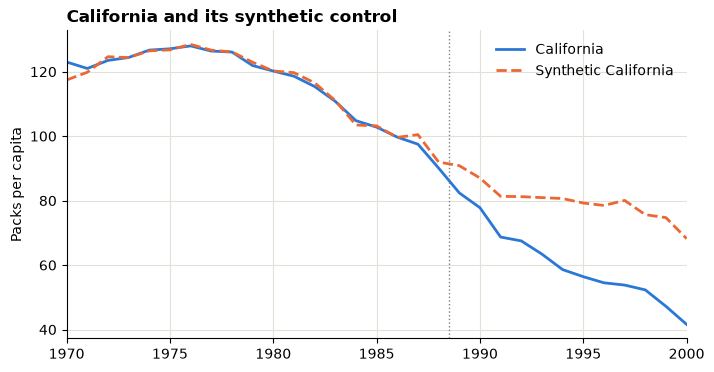

In [3]:
plot_trajectory("California", sales["California"] - gap, "California and its synthetic control")

## Is the effect real? Placebo tests

A first check is the in-time placebo. Pretend Proposition 99 started in 1980, fit the synthetic control on 1970-1979 only, and look at the gap over 1980-1988. No program was in place then, so the gap should be near zero. It is not exactly zero: the average gap is -3.4 packs, with the largest yearly gap 9.4. Next to the real average gap of -19.5 packs over 1989-2000, that is small. The held-out fits point the same way. Weights fitted on 1970 up to 1982, 1983, 1984, or 1985, then used to estimate the 1989-2000 effect, give average gaps between -18.9 and -20.2. Leave-one-out moves the estimate less: dropping Connecticut gives -20.5, dropping Montana gives -18.0, and the other drops sit in between. The size of the effect does not depend on how well the weights fit their own years.

The in-space placebo is where the significance gets less settled. ADH's statistic is the post/pre MSPE ratio. With this fit, California's ratio is 154.8, which ranks 3 of 39, p = 0.077. Missouri and Virginia rank above it. The reason is visible in the rolling-origin comparison. The ratio divides by in-sample pre-period MSPE, and that denominator is optimistic for every fitted state. California's in-sample error is 2.74, its rolling-origin error 11.96, about 4 times. Missouri's in-sample error is 0.19, rolling-origin 3.02, about 16 times. Virginia's is 0.67 in-sample, 10.97 rolling-origin, about 16 times. The in-sample error flatters Missouri and Virginia far more than California, so the ratio test favours them.

Two other statistics give a different picture. Among the 32 states whose pre-period MSPE is within 5 times California's, California's average gap is the most negative: rank 1, p = 0.031. With held-out denominators, California's ratio rank is 5 to 7 of 39, p = 0.128 to 0.179. So across these test statistics, p runs from 0.031 to 0.179, while the effect size stays near -19.5 in every version. The size of the effect is not in doubt. The strength of the placebo evidence depends on the test statistic. This notebook does not re-test ADH's own predictor-based weights with held-out errors, so it does not claim their p = 1/39 is wrong. It shows that a single p-value overstates how settled the significance is.

In [4]:
placebo_gaps = pd.DataFrame({state: synthetic_control(state, [d for d in DONORS if d != state])[1]
                             for state in ["California", *DONORS]})
tests = pd.DataFrame({"pre-1989 MSPE": placebo_gaps.apply(pre_mspe),
                      "post/pre MSPE ratio": placebo_gaps.apply(mspe_ratio),
                      "average gap": placebo_gaps.loc[START:].mean()}
                     ).sort_values("post/pre MSPE ratio", ascending=False)

ratio_rank = tests.index.get_loc("California") + 1
well_fitted = tests[tests["pre-1989 MSPE"] <= 5 * tests.loc["California", "pre-1989 MSPE"]]
gap_rank = int(well_fitted["average gap"].rank().loc["California"])
print(f"Ratio test: California ranks {ratio_rank} of {len(tests)}, p = {ratio_rank / len(tests):.3f}")
print(f"Average gap among the {len(well_fitted)} states fitted within 5x California's pre-1989 MSPE: "
      f"California ranks {gap_rank}, p = {gap_rank / len(well_fitted):.3f}")
tests.head(5).round(2)

Ratio test: California ranks 3 of 39, p = 0.077
Average gap among the 32 states fitted within 5x California's pre-1989 MSPE: California ranks 1, p = 0.031


,pre-1989 MSPE,post/pre MSPE ratio,average gap
Missouri,0.19,572.38,9.04
Virginia,0.67,393.13,-15.54
California,2.74,154.75,-19.51
Georgia,1.19,82.11,-8.81
Texas,3.68,66.89,-14.18


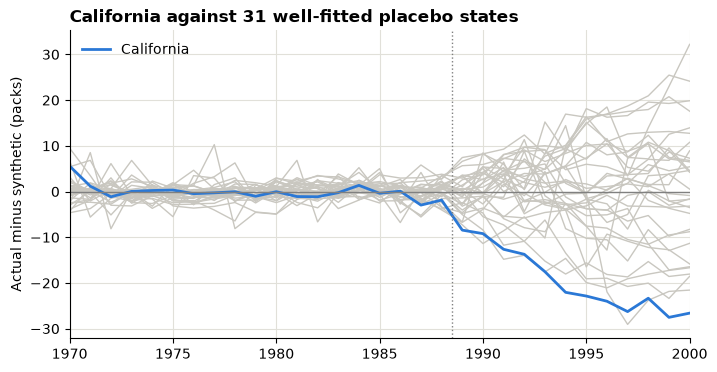

In [5]:
fig, ax = plt.subplots()
for state in well_fitted.index.drop("California"):
    ax.plot(placebo_gaps.index, placebo_gaps[state], color=GRAY, linewidth=1)
ax.plot(placebo_gaps.index, placebo_gaps["California"], color=BLUE, label="California")
ax.axhline(0, color="gray", linewidth=1)
ax.axvline(START - 0.5, color="gray", linestyle=":", linewidth=1)
ax.set(title=f"California against {len(well_fitted) - 1} well-fitted placebo states",
       ylabel="Actual minus synthetic (packs)", xlim=(sales.index[0], sales.index[-1]))
ax.legend();

In [6]:
_, fake_gap = synthetic_control("California", DONORS, start=1980, data=sales.loc[:START - 1])
print(f"Pretend start in 1980: average gap {fake_gap.loc[1980:].mean():.2f}, "
      f"largest yearly gap {fake_gap.loc[1980:].abs().max():.2f}")

leave_one_out = pd.Series({dropped: synthetic_control("California", [d for d in DONORS if d != dropped])[1]
                           .loc[START:].mean() for dropped in weights[weights > 0.001].index})
leave_one_out.sort_values().round(2).rename("average gap without this donor")

Pretend start in 1980: average gap -3.37, largest yearly gap 9.35


Connecticut     -20.51
New Hampshire   -19.78
Colorado        -19.60
Nevada          -19.17
Utah            -19.14
Montana         -17.97
Name: average gap without this donor, dtype: float64

In [7]:
def rolling_origin_mspe(state, donors, first_test=1979, step=2):
    """Fit on the years before each two-year window, forecast that window, average the squared errors."""
    errors = [synthetic_control(state, donors, start=s, data=sales.loc[:START - 1])[1].loc[s:s + step - 1] ** 2
              for s in range(first_test, START, step)]
    return pd.concat(errors).mean()


optimism = pd.DataFrame({state: {"in-sample pre-1989 MSPE": pre_mspe(placebo_gaps[state]),
                                 "rolling-origin MSPE": rolling_origin_mspe(state, [d for d in DONORS if d != state])}
                         for state in ["California", "Missouri", "Virginia"]}).T
optimism["out-of-sample / in-sample"] = optimism["rolling-origin MSPE"] / optimism["in-sample pre-1989 MSPE"]
display(optimism.round(2))


def held_out(fit_end):
    """Fit every state on 1970-fit_end; the remaining pre-1989 years become an honest ratio denominator."""
    gaps = {state: synthetic_control(state, [d for d in DONORS if d != state], start=fit_end + 1)[1]
            for state in ["California", *DONORS]}
    ratios = pd.Series({state: (g.loc[START:] ** 2).mean() / (g.loc[fit_end + 1:START - 1] ** 2).mean()
                        for state, g in gaps.items()}).sort_values(ascending=False)
    return {"California's average gap": gaps["California"].loc[START:].mean(),
            "California's ratio rank": ratios.index.get_loc("California") + 1}


held_out_fits = pd.DataFrame({f"fit 1970-{fit_end}": held_out(fit_end) for fit_end in range(1982, 1986)}).T
held_out_fits.round(2)

,in-sample pre-1989 MSPE,rolling-origin MSPE,out-of-sample / in-sample
California,2.74,11.96,4.36
Missouri,0.19,3.02,15.77
Virginia,0.67,10.97,16.48


,California's average gap,California's ratio rank
fit 1970-1982,-19.88,5.0
fit 1970-1983,-19.54,5.0
fit 1970-1984,-20.22,7.0
fit 1970-1985,-18.88,5.0


## Beyond the paper: was Nevada treated too?

Nevada is the donor that most invites suspicion. It gets a weight of 0.205 in this fit, it borders California, and its per-capita sales are far above the donor average: 141.9 packs per resident in 1988 against 113.8 for the average donor. Sales are counted where they happen, so a Californian crossing the border to buy cigarettes would show up in Nevada's numbers, not California's. That would raise synthetic California and make the estimated effect look too large. The opposite channel runs through Nevada's own sales: if Californian visitors bought fewer cigarettes after Proposition 99, Nevada's sales would fall, pulling synthetic California down and making the estimated effect too small. The two channels point in opposite directions.

Nevada's own synthetic control suggests the second channel is the one that matters. Fitting Nevada with California excluded gives a poor fit, a pre-period MSPE of 46.2, so the gap is not measured cleanly. Still, Nevada's average gap over 1989-2000 is -7.5, and its post/pre ratio ranks 33 of 39, so on its own the gap is not unusual. Netting Nevada's post-1988 gap, times its weight, out of synthetic California gives an average gap of -21.0 and a 2000 gap of -28.8, slightly larger than the main estimate. Refitting without Nevada in the donor pool gives -19.2, barely different, because the other donors take Nevada's place.

In short, I see no sign of the cross-border problem that would inflate the effect. If anything, the effect is understated.

Nevada sales per resident, 1988        141.90
Donor average, 1988                    113.82
Nevada's own average gap                -7.48
Nevada's pre-1989 MSPE                  46.19
California, Nevada's gap netted out    -21.05
California, refit without Nevada       -19.17
dtype: float64

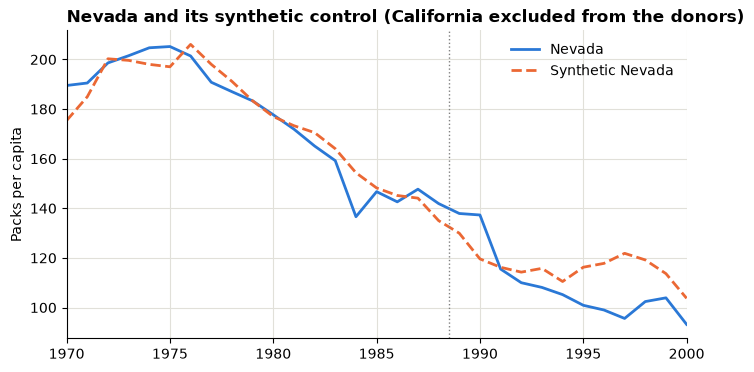

In [8]:
nevada_gap = placebo_gaps["Nevada"]
plot_trajectory("Nevada", sales["Nevada"] - nevada_gap,
                "Nevada and its synthetic control (California excluded from the donors)")

netted_gap = gap + weights["Nevada"] * nevada_gap.where(nevada_gap.index >= START, 0)
_, gap_without_nevada = synthetic_control("California", [d for d in DONORS if d != "Nevada"])
pd.Series({"Nevada sales per resident, 1988": sales.loc[1988, "Nevada"],
           "Donor average, 1988": sales.loc[1988, DONORS].mean(),
           "Nevada's own average gap": nevada_gap.loc[START:].mean(),
           "Nevada's pre-1989 MSPE": pre_mspe(nevada_gap),
           "California, Nevada's gap netted out": netted_gap.loc[START:].mean(),
           "California, refit without Nevada": gap_without_nevada.loc[START:].mean()}).round(2)

## What I conclude

I am confident about the size of the effect. The average gap over 1989-2000 is -19.5 packs per capita with my sales-only fit, and -19.0 when I apply ADH's published weights to the same data. The held-out fits, where weights are fitted on 1970 up to 1982, 1983, 1984 or 1985, give average gaps between -20.2 and -18.9. The effect stays near -19.5 in every version, so the size is robust out of sample.

What is less settled is the statistical significance. The p-value runs from 0.031 to 0.179 depending on the test statistic. The in-space placebo with the in-sample ratio gives p = 0.077, and restricting to states with a comparable pre-period fit gives p = 0.031. The held-out fits give p = 0.128 to 0.179. ADH's p = 1/39 uses their predictor-based weights with the in-sample ratio; I did not re-test their weights with held-out errors, so I can only say that a single p-value overstates how settled the significance is, not that their p is wrong.

The Nevada check points to an understated effect rather than an inflated one. Nevada has a large weight in my fit, and its own synthetic control fits poorly, but its post-1988 gap is negative. Netting that gap out of synthetic California makes the average gap -21.0. Cross-border buying by Californians would raise Nevada's sales and make the estimated effect too large; the negative gap fits Californian visitors buying less, which biases the estimate toward zero.

Sales are not smoking, and some of the fall may be tax avoidance outside Nevada. The estimate covers the whole Proposition 99 package, not only the tax. The p-values are permutation ranks among 39 states, so they measure the strength of the placebo evidence, not a formal sampling probability.

In [9]:
def r(x, digits=1):
    return round(float(x), digits)


summary = {
    "weights": {k: r(v, 3) for k, v in weights[weights > 0.001].sort_values(ascending=False).items()},
    "pre_mspe": r(pre_mspe(gap), 2), "average_gap": r(gap.loc[START:].mean()), "gap_2000": r(gap[2000]),
    "relative_effect_pct": r(100 * gap.loc[START:].mean() / (sales["California"] - gap).loc[START:].mean()),
    "adh_pre_mspe": r(pre_mspe(adh_gap), 2), "adh_average_gap": r(adh_gap.loc[START:].mean()),
    "adh_gap_2000": r(adh_gap[2000]), "adh_ratio": r(mspe_ratio(adh_gap)),
    "n_units": len(tests), "california_ratio": r(tests.loc["California", "post/pre MSPE ratio"]),
    "ratio_rank": ratio_rank, "ratio_p": r(ratio_rank / len(tests), 3),
    "above_california": {s: {"pre_mspe": r(tests.loc[s, "pre-1989 MSPE"], 2),
                             "ratio": r(tests.loc[s, "post/pre MSPE ratio"])}
                         for s in tests.index[:ratio_rank - 1]},
    "well_fitted_n": len(well_fitted), "gap_rank": gap_rank, "gap_p": r(gap_rank / len(well_fitted), 3),
    "in_time_average_gap": r(fake_gap.loc[1980:].mean()), "in_time_max_gap": r(fake_gap.loc[1980:].abs().max()),
    "leave_one_out": {k: r(v) for k, v in leave_one_out.sort_values().items()},
    "optimism": {s: {"in_sample": r(row["in-sample pre-1989 MSPE"], 2), "rolling_origin": r(row["rolling-origin MSPE"], 2),
                     "factor": r(row["out-of-sample / in-sample"], 0)} for s, row in optimism.iterrows()},
    "held_out": {k: {"average_gap": r(row["California's average gap"]), "ratio_rank": int(row["California's ratio rank"])}
                 for k, row in held_out_fits.iterrows()},
    "held_out_gap_range": [r(held_out_fits["California's average gap"].min()),
                           r(held_out_fits["California's average gap"].max())],
    "held_out_rank_range": [int(held_out_fits["California's ratio rank"].min()),
                            int(held_out_fits["California's ratio rank"].max())],
    "held_out_p_range": [r(held_out_fits["California's ratio rank"].min() / len(tests), 3),
                         r(held_out_fits["California's ratio rank"].max() / len(tests), 3)],
    "nevada_weight": r(weights["Nevada"], 3), "nevada_1988": r(sales.loc[1988, "Nevada"]),
    "donor_average_1988": r(sales.loc[1988, DONORS].mean()),
    "nevada_average_gap": r(nevada_gap.loc[START:].mean()), "nevada_pre_mspe": r(pre_mspe(nevada_gap)),
    "nevada_ratio_rank": tests.index.get_loc("Nevada") + 1,
    "netted_average_gap": r(netted_gap.loc[START:].mean()), "netted_gap_2000": r(netted_gap[2000]),
    "without_nevada_average_gap": r(gap_without_nevada.loc[START:].mean()),
}
print(json.dumps(summary, indent=1))

{
 "weights": {
  "Utah": 0.394,
  "Montana": 0.232,
  "Nevada": 0.205,
  "Connecticut": 0.109,
  "New Hampshire": 0.045,
  "Colorado": 0.015
 },
 "pre_mspe": 2.74,
 "average_gap": -19.5,
 "gap_2000": -26.6,
 "relative_effect_pct": -24.4,
 "adh_pre_mspe": 3.09,
 "adh_average_gap": -19.0,
 "adh_gap_2000": -25.7,
 "adh_ratio": 128.4,
 "n_units": 39,
 "california_ratio": 154.8,
 "ratio_rank": 3,
 "ratio_p": 0.077,
 "above_california": {
  "Missouri": {
   "pre_mspe": 0.19,
   "ratio": 572.4
  },
  "Virginia": {
   "pre_mspe": 0.67,
   "ratio": 393.1
  }
 },
 "well_fitted_n": 32,
 "gap_rank": 1,
 "gap_p": 0.031,
 "in_time_average_gap": -3.4,
 "in_time_max_gap": 9.4,
 "leave_one_out": {
  "Connecticut": -20.5,
  "New Hampshire": -19.8,
  "Colorado": -19.6,
  "Nevada": -19.2,
  "Utah": -19.1,
  "Montana": -18.0
 },
 "optimism": {
  "California": {
   "in_sample": 2.74,
   "rolling_origin": 11.96,
   "factor": 4.0
  },
  "Missouri": {
   "in_sample": 0.19,
   "rolling_origin": 3.02,
   "facto